# Context-managed research: does curation beat the full history?
*Agentic AI Systems · Harness Design II · symbolic regression on LLM-SRBench*

Each step, the curator selects the earlier steps that matter; the meta-reasoner sees only those and writes a work
order; a fresh executor turns it into **one equation**; the history keeps everything. AutoResearch (H1) instead keeps
one agent with the full history.

1. **Curation vs. full history:** does H3 beat AutoResearch as runs get longer?
2. **Context per decision:** does curation keep the context small?

**Curator prompt:**

> You curate the research history of a team discovering the equation behind the data.
> You see every earlier step, one per line. Select the steps (at most 5) that matter most for
> deciding what to investigate next: for example the best results, directions that failed,
> and evidence about what has not been tried. Call select_steps with their numbers.

**Meta-reasoner prompt:**

> You direct a research process discovering the equation behind the data.
> You do not see the full history, only a curated view of it: the best equations so far, the
> last step, and earlier steps selected by a curator. Choose the most useful next step and
> write a work order for an executor, who starts fresh, sees only the task and your work
> order, and proposes one equation. Call assign_work, or finish if no better equation can
> be found.

**Executor prompt:**

> You are an executor in a research team. You receive one work order.
> Propose one equation that follows it and evaluate it with evaluate_equation.

**Setup:** 129 tasks × 4 seeds; 16 evaluations; both harnesses may stop early (`finish`); AutoResearch with reasoning.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from sr_harness import load_config
from sr_harness.analysis import history, plots
from sr_harness.benchmark import load_tasks
from sr_harness.experiments.runner import run_grid
from sr_harness.llm import LLMClient

LIVE = False        # False: replay the recorded runs; True: run the experiment (OpenRouter + HF login)
H1, H3 = "baseline_autoresearch", "context_managed"
ROOT = "runs" if LIVE else "recorded"
OUT = {H1: f"{ROOT}/reasoning_ablation_16", H3: f"{ROOT}/context_managed_16"}
N_TASKS, SEEDS, BUDGET = 129, [0, 1, 2, 3], 16

cfg = load_config()
cfg["benchmark"]["n_tasks"] = N_TASKS
cfg["experiment"]["budget"]["max_evaluations"] = BUDGET
print("model:", cfg["model"]["model"])

model: openai/gpt-oss-20b


## 1. Run the experiment (or load the recorded runs)
129 tasks × 4 seeds × 2 harnesses = 1032 runs.

In [2]:
if LIVE:
    tasks = load_tasks(cfg["benchmark"])
    make_llm = lambda logger, seed: LLMClient(cfg["model"], logger=logger, seed=seed)
    for h in (H1, H3):
        run_grid(tasks, [h], SEEDS, cfg, make_llm, OUT[h])

results = [r for h in (H1, H3) for r in plots.load_results(OUT[h]) if r["harness"] == h]
print(len(results), "runs:", pd.Series([r["harness"] for r in results]).value_counts().to_dict())

1032 runs: {'baseline_autoresearch': 516, 'context_managed': 516}


## 2. Curation vs. full history: does H3 beat AutoResearch as runs get longer?
Score after each evaluation of the best equation so far. Bands: 95% CI over tasks.

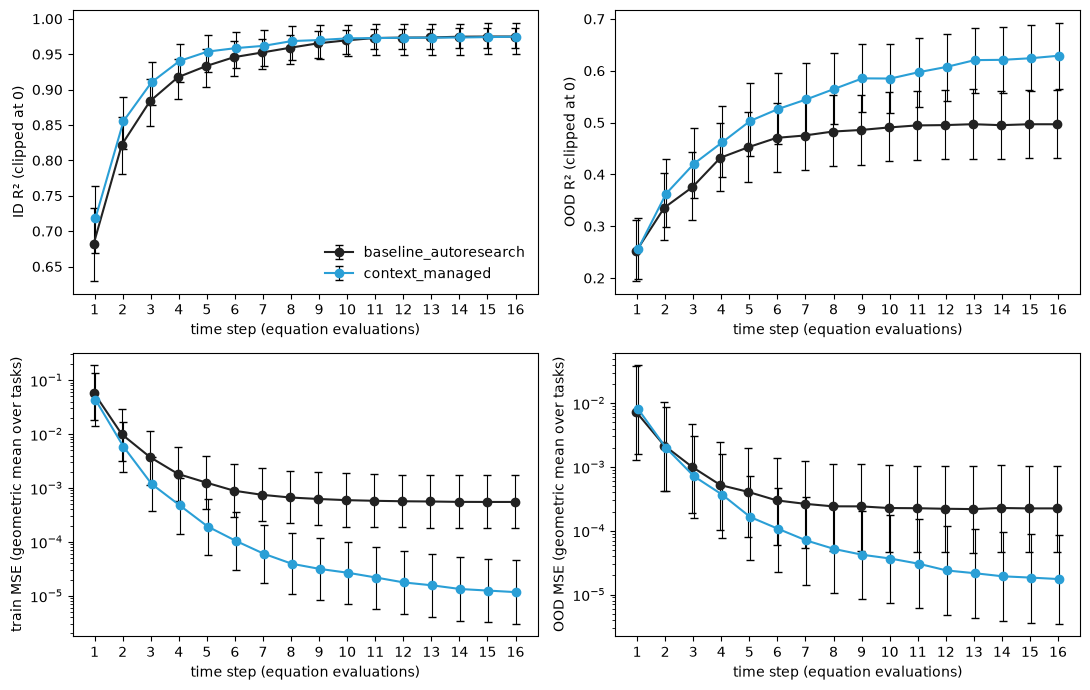

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, metric in zip(axes.flat, ["train_dist_r2", "ood_r2", "train_mse", "ood_mse"]):
    plots.plot_vs_steps(results, metric, max_step=BUDGET, ax=ax)
for ax in list(axes.flat)[1:]:
    ax.get_legend().remove()
fig.tight_layout()
plt.show()

### R² vs. tokens
The same runs against compute: tokens of all model calls (H3: curator, meta-reasoner and executor).

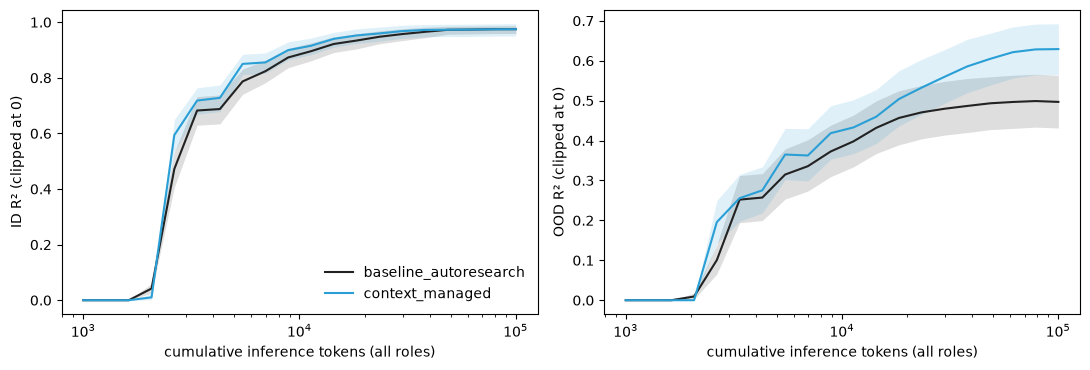

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
plots.plot_vs_tokens(results, metric="train_dist_r2", ax=axes[0])
plots.plot_vs_tokens(results, metric="ood_r2", ax=axes[1])
axes[1].get_legend().remove()
fig.tight_layout()
plt.show()

### Curation, or a longer search?
A run that stops early keeps its last answer, so the AutoResearch curves are flat once its runs stop. How long does
each harness search? Neither is told to use its budget: both may call `finish` "if no better equation can be found".
AutoResearch without reasoning (2 seeds, not in the plots above) is added for comparison.

In [5]:
NR = "baseline_autoresearch_no_reasoning"
no_reasoning = [r for r in plots.load_results(OUT[H1]) if r["harness"] == NR]
stopping = pd.DataFrame([{"harness": h, "runs": len(rs),
                          "evaluations used": sum(r["evaluations"] for r in rs) / len(rs),
                          f"used all {BUDGET}": sum(r["evaluations"] == BUDGET for r in rs) / len(rs)}
                         for h, rs in [(H1, [r for r in results if r["harness"] == H1]), (NR, no_reasoning),
                                       (H3, [r for r in results if r["harness"] == H3])]]).set_index("harness")
stopping.round(2)

,runs,evaluations used,used all 16
harness,,,
baseline_autoresearch,516,5.47,0.02
baseline_autoresearch_no_reasoning,258,11.83,0.43
context_managed,516,13.11,0.47


Does H3 score better at the same step, or only by searching longer? OOD R² (clipped at 0), H3 − AutoResearch,
paired by task (seeds averaged; 95% CI = mean ± 1.96·sd/√n).

In [6]:
steps = plots.step_table(results, "ood_r2", BUDGET).set_index(["harness", "task", "seed", "step"])["value"]
h1_evals = {(r["task_id"], r["seed"]): max(1, r["evaluations"]) for r in results if r["harness"] == H1}
pairs = [k for k in h1_evals if (H3, *k, 1) in steps.index]

def paired_diff(h3_step, h1_step):
    d = pd.Series({k: steps[(H3, *k, h3_step(k))] - steps[(H1, *k, h1_step(k))] for k in pairs})
    per_task = d.groupby(level=0).mean()
    half = 1.96 * per_task.std() / len(per_task) ** 0.5
    return {"H3 − AutoResearch": round(per_task.mean(), 3),
            "95% CI": f"[{per_task.mean() - half:+.3f}, {per_task.mean() + half:+.3f}]",
            "H3 better / worse (tasks)": f"{(per_task > 0).mean():.0%} / {(per_task < 0).mean():.0%}"}

pd.DataFrame({f"final (step {BUDGET})": paired_diff(lambda k: BUDGET, lambda k: BUDGET),
              "both at step 3": paired_diff(lambda k: 3, lambda k: 3),
              "both at step 5": paired_diff(lambda k: 5, lambda k: 5),
              "H3 stopped where AutoResearch stopped": paired_diff(lambda k: h1_evals[k], lambda k: h1_evals[k])}).T

,H3 − AutoResearch,95% CI,H3 better / worse (tasks)
final (step 16),0.132,"[+0.087, +0.178]",70% / 25%
both at step 3,0.045,"[+0.006, +0.084]",43% / 29%
both at step 5,0.051,"[+0.007, +0.095]",51% / 32%
H3 stopped where AutoResearch stopped,-0.041,"[-0.079, -0.003]",35% / 50%


## 3. Context per decision: does curation keep the context small?
Input tokens of each model call, by step. AutoResearch resends its whole history; in H3 only the curator reads the
earlier steps (one line each).

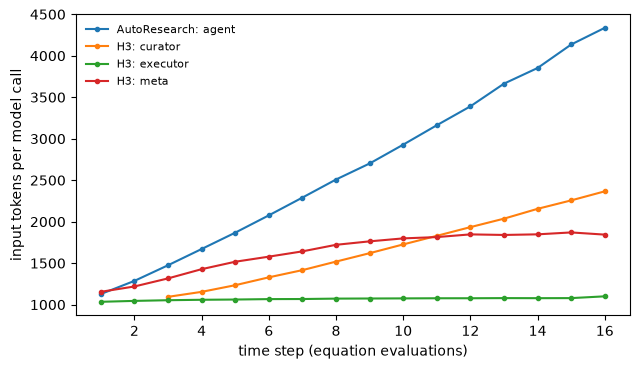

In [7]:
calls = pd.concat([history.calls_by_step(OUT[h], [r for r in results if r["harness"] == h]) for h in (H1, H3)])
calls["who"] = calls["harness"].map({H1: "AutoResearch", H3: "H3"}) + ": " + calls["role"]
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for who, d in calls[calls.step <= BUDGET].groupby("who"):
    m = d.groupby("step")["input_tokens"].mean()
    ax.plot(m.index, m.values, marker=".", label=who)
ax.set(xlabel="time step (equation evaluations)", ylabel="input tokens per model call")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

## 4. A trace: H3
Seed 0, on the task where H3 and AutoResearch differ most (chosen on purpose, not a typical task). Each step: the
earlier steps the curator selected, the work order, and the equation with its train R².

In [8]:
def run(h, task, seed=0):
    return next(r for r in results if r["harness"] == h and r["task_id"] == task and r["seed"] == seed)

def r2(r, split):
    return max(0.0, r["scores"][split]["r2"]) if r["scores"][split] else 0.0

done = {(r["harness"], r["task_id"]) for r in results if r["seed"] == 0 and r["evaluations"] >= 3}
both = sorted(t for h, t in done if h == H3 and (H1, t) in done)
task = max(both, key=lambda t: abs(r2(run(H3, t), "train_dist") - r2(run(H1, t), "train_dist")))

r = run(H3, task)
print(f"task: {task}   H3: ID R² = {r2(r, 'train_dist'):.3f}, OOD R² = {r2(r, 'ood'):.3f}   "
      f"(AutoResearch: {r2(run(H1, task), 'train_dist'):.3f}, {r2(run(H1, task), 'ood'):.3f})\n")
selected = {}
for e in map(json.loads, open(Path(OUT[H3], "logs", r["run_id"] + ".jsonl"))):
    if e["event"] == "curation":
        selected[e["step"]] = e["selected"]
    elif e["event"] == "executor_start":
        print(f"step {e['step']}   curator selected: {selected.get(e['step'], [])}")
        print(f"  work order: {e['work_order'][:150]}")
    elif e["event"] == "evaluation":
        score = f"train R² {e['train_r2']:.3f}" if e["error"] is None else f"error: {e['error'][:50]}"
        print(f"  equation:   {e['expression'][:100]}   ({score})")
    elif e["event"] == "stop":
        print(f"stopped: {e['role']} called finish" if e["reason"] != "no tool call" else "stopped: no tool call")

task: chem_react/CRK20   H3: ID R² = 0.000, OOD R² = 0.000   (AutoResearch: 0.985, 0.000)

step 1   curator selected: []
  work order: c0*exp(-c1*t) + c2*A
  equation:   c0*exp(-c1*t) + c2*A   (train R² 0.808)
step 2   curator selected: []
  work order: c0*exp(-c1*t)*A + c2
  equation:   c0*exp(-c1*t)*A + c2   (train R² 0.896)
step 3   curator selected: [1]
  work order: c0*A*exp(-c1*t)+c2*A+c3
  equation:   c0*A*exp(-c1*t)+c2*A+c3   (train R² 0.979)
step 4   curator selected: [1, 2]
  work order: c0*A*exp(-c1*t)+c2*A+c3 + c4*t
  equation:   c0*A*exp(-c1*t)+c2*A+c3+c4*t   (train R² 0.983)
step 5   curator selected: [1, 2, 3]
  work order: c0*A*exp(-c1*t)+c2*A+c3+c4*t + c5*t**2
  equation:   c0*A*exp(-c1*t)+c2*A+c3+c4*t + c5*t**2   (train R² 0.983)
step 6   curator selected: [2, 3, 4]
  work order: c0*A*exp(-c1*t)+c2*A+c3+c4*t+c5/t
  equation:   c0*A*exp(-c1*t)+c2*A+c3+c4*t+c5/t   (train R² 0.984)
step 7   curator selected: [3, 4, 5]
  work order: c0*A*exp(-c1*t)+c2*A+c3+c4*t+c5*A/t
  e